# GreenPy Section

### Propriedades geométricas de figuras planas utilizando o Teorema de Green

Criado por:  
**Autores mantidos em sigilo durante processo de submissão à revista RENOTE**  
**Instituição mantida em sigilo**
            
Data da última revisão: outubro/2026  


In [1]:
# Limpa todas variáveis 
%reset -f

# Importa bibliotecas:
import numpy as np
import math as m
import re
import sys
import os
import matplotlib.pyplot as plt
from matplotlib.path import Path
from matplotlib.patches import PathPatch

# Importa módulos próprios:
from greenpy_functions import *

# Podem ser importadas durante a execução do código, se necessárias (lazy import):
# scipy, pandas, ipywidgets, IPython.display 

## 1 - Entrada de dados  

<p style="font-size:14px;">Na célula abaixo, primeiramente escolha uma das opções para a entrada de dados:</p>

<p style="font-size:14px;"> 
<b>e = 1</b> → Leitura de arquivo de dados externo <code style="font-size:13px;">.txt</code><br>
<b>e = 2</b> → Usuário digita dados respondendo perguntas na tela<br>
<b>e = 3</b> → Usuário digita dados em planilha dinâmica na tela
</p>

<details>
<summary><em style="font-size:14px;">Clique aqui para mais detalhes sobre o arquivo de dados</em></summary>

<br>

<p style="font-size:13px;">
  A ideia básica da entrada de dados é representar os contornos da seção e dos furos como sequências de caminhos simples: segmentos de reta, arcos de circunferência ou parábolas.
</p>

<p style="font-size:13px;">
  Esses caminhos devem ser descritos por linhas de dados em um arquivo <code style="font-size:13px;">.txt</code>. Dependendo da forma de entrada escolhida (<code style="font-size:13px;">e = 1</code>, <code style="font-size:13px;">2</code> ou <code style="font-size:13px;">3</code>), esse arquivo pode ser preenchido diretamente pelo usuário ou gerado pelo programa a partir de outras interfaces.
</p>

<p style="font-size:13px;">
  As coordenadas dos pontos devem ser definidas em relação a um sistema de eixos cartesianos de referência (<code>x<sub>ref</sub></code>, <code>y<sub>ref</sub></code>), arbitrado pelo usuário. A escolha do posicionamento desse sistema é livre, mas é essencial manter a coerência, referenciando todos os pontos ao mesmo par de eixos.
</p>

<p style="font-size:13px;">
  O preenchimento do arquivo deve seguir as orientações abaixo.
</p>

<ul style="font-size:13px;">
  <li>Insira uma linha de dados por caminho, na sequência correta:
    <ul style="font-size:13px; margin-top:4px; margin-bottom:8px; list-style-type:none; padding-left:1em;">
      <li>→ Caminhos do contorno externo no sentido anti-horário;</li>
      <li>→ Caminhos dos furos no sentido horário.</li>
    </ul>
  </li>
  <li>Cada linha em branco delimita o final de um grupo de caminhos (contorno ou furo):
    <ul style="font-size:13px; margin-top:4px; margin-bottom:8px; list-style-type:none; padding-left:1em;">
      <li>→ Não deixe linhas em branco entre caminhos de um mesmo grupo;</li>
      <li>→ Deixe uma linha em branco entre o caminho final de um grupo e o caminho inicial de outro.</li>
    </ul>
  </li>
  <li>Linhas iniciadas com <code style="font-size:13px;">#</code> são ignoradas pelo programa (podem ser usadas para anotações).</li>
</ul>

<p style="font-size:13px;">As linhas de dados dos caminhos – com valores separados por espaços – devem seguir o formato abaixo:</p>

<pre style="font-size:13px; background-color:#f5f5f5; padding:6px; border-radius:6px;">tipo xi yi [θi θf raio | xp yp]</pre>

<p style="font-size:13px; margin-top:6px;"><b>Onde:</b></p>
<ul style="font-size:13px;">
  <li><code style="font-size:13px;">tipo</code>: define o tipo de caminho, com os seguintes valores possíveis:
    <ul style="font-size:13px; margin-top:4px;">
      <li><b>1</b> – segmento de reta</li>
      <li><b>2</b> – arco de circunferência</li>
      <li><b>3</b> – parábola do tipo y = f(x)</li>
      <li><b>4</b> – parábola do tipo x = f(y)</li>
    </ul>
  </li>
  <li><code style="font-size:13px;">xi</code>, <code style="font-size:13px;">yi</code>: coordenadas do ponto inicial do caminho</li>
  <li><code style="font-size:13px;">θi</code>, <code style="font-size:13px;">θf</code>, <code style="font-size:13px;">raio</code>: ângulos inicial e final (em graus) e raio. Apenas para arcos (tipo = 2)</li>
  <li><code style="font-size:13px;">xp</code>, <code style="font-size:13px;">yp</code>: coordenadas de um ponto intermediário. Apenas para parábolas (tipo = 3 ou tipo = 4)</li>
</ul>
<p style="font-size:13px;"><b>Exemplo:</b></p>
<ul style="font-size:13px;">
  <li>Contorno externo quadrado (lado 10), definido por 4 segmentos de reta;</li>
  <li>Furo circular central (raio 1), definido por um arco completo de 360° no sentido horário;</li>
  <li>Origem do sistema de eixos posicionada no vértice inferior esquerdo do quadrado.</li>
</ul>
<pre style="font-size:13px; background-color:#f5f5f5; padding:6px; border-radius:6px;">
1 0 0
1 10 0
1 10 10
1 0 10

2 6 5 360 0 1
</pre>
</details>
<br>

<p style="font-size:14px;">Defina também os seguintes parâmetros:</p>
<ul style="font-size:14px;">
  <li><code style="font-size:13px;">nome_da_secao</code>: nome da seção a ser analisada e da pasta onde os resultados serão salvos.</li>
  <li><code style="font-size:13px;">nome_do_arquivo</code>: nome do arquivo de dados que será lido ou gerado (ex.: <code style="font-size:13px;">'dados_green.txt'</code>).</li>
  <li><code style="font-size:13px;">unidade</code>: define a unidade de comprimento. Para não mostrar unidades, use <code style="font-size:13px;">''</code> (string vazia).</li>
</ul>

<p style="font-size:14px;">A função <code style="font-size:13px;">escolha_dados</code> será executada com os parâmetros escolhidos.</p>

<p style="font-size:14px;">Após as escolhas, <b>execute a célula abaixo</b> para iniciar o processo de entrada de dados.</p>



In [2]:
# Tipo de entrada de dados: 
e = 2

# Nome da seção que será analisada (e da pasta onde resultados serão salvos):
nome_da_secao = 'exemplo teste'                 

# Nome do arquivo de dados a ser lido ou gerado
nome_do_arquivo = 'dados_green.txt'         

# Unidades:
unidade = 'cm' # unidades válidas: ('', 'mm','cm','dm','m','dam','hm','km','pol','in' ou 'ft')
unidades = dict_unidades(unidade) 

# Inicia programa:
escolha_dados(e, nome_do_arquivo, jupyter=True, pasta_destino = nome_da_secao)


Os dados serão lidos do arquivo 'dados_green.txt' do diretório atual.
Os resultados serão salvos na pasta 'exemplo teste'.


## 2 - Leitura e conferência de dados  

<p style="font-size:14px;">Na célula abaixo, você pode ajustar os parâmetros opcionais de visualização da figura com os caminhos e definir se deseja salvar os arquivos auxiliares.</p>  

<details>
<summary style="font-size:14px;"><i> Clique aqui para visualizar a descrição dos parâmetros disponíveis</i></summary>  

<br>

<ul style="font-size:14px;">  
  <li><code style="font-size:13px;">tamanho_figura</code>: define o tamanho da figura.</li>  
  <li><code style="font-size:13px;">texto_caminho</code>: exibe ou oculta os rótulos dos caminhos (<code style="font-size:13px;">True</code> ou <code style="font-size:13px;">False</code>).</li>  
  <li><code style="font-size:13px;">tamanho_texto</code>: fator de escala para o tamanho dos rótulos.</li>  
  <li><code style="font-size:13px;">offset_texto</code>: deslocamento dos textos em relação ao caminho.</li>  
  <li><code style="font-size:13px;">tamanho_titulo</code>: fator de escala para o título da figura.</li>  
  <li><code style="font-size:13px;">tamanho_eixos</code>: fator de escala para os valores dos eixos.</li>  
  <li><code style="font-size:13px;">cor_caminhos</code>: cor dos caminhos (ex: <code style="font-size:13px;">'royalblue'</code> ou <code style="font-size:13px;">choose_color(100,100,240)</code>).</li>  
  <li><code style="font-size:13px;">espessura</code>: espessura das linhas dos caminhos.</li>  
  <li><code style="font-size:13px;">tamanho_pontos</code>: tamanho dos marcadores de pontos.</li>  
  <li><code style="font-size:13px;">grade</code>: exibe ou oculta a grade na figura (<code style="font-size:13px;">True</code> ou <code style="font-size:13px;">False</code>).</li>  
</ul>  

<p style="font-size:14px;">Além disso, é possível definir:</p>  
<ul style="font-size:14px;">  
  <li><code style="font-size:13px;">separador_decimal</code> e <code style="font-size:13px;">separador_milhar</code>: personalização dos separadores numéricos.</li>  
  <li><code style="font-size:13px;">salvar_dados_green</code>: salva uma cópia do arquivo original de dados na pasta destino.</li>  
  <li><code style="font-size:13px;">salvar_dados_lidos</code>: salva os dados já interpretados em um novo arquivo <code style="font-size:13px;">.txt</code>.</li>  
  <li><code style="font-size:13px;">salvar_figura</code>: salva a figura gerada nos formatos <code style="font-size:13px;">.png</code> e <code style="font-size:13px;">.svg</code>.</li>  
</ul>  
</details>  

<br>

<p style="font-size:14px;">A função <code style="font-size:13px;">leitura_de_dados</code> será chamada para interpretar o conteúdo do arquivo de dados e armazenar os caminhos em memória.</p>  

<p style="font-size:14px;">Em seguida, a função <code style="font-size:13px;">conferencia_dados_jupyter</code> será chamada com os parâmetros configurados.</p>  

<p style="font-size:14px;">Após configurar os parâmetros, <b>execute a célula</b> para que o programa leia o arquivo e apresente os dados interpretados.</p>  

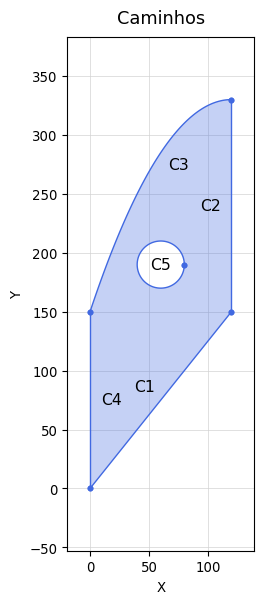


Dados de entrada lidos pelo programa:

=== Caminhos de contorno: ===

--- Caminho 1: ---
Tipo: Segmento de Reta
Coordenadas (x;y):
Ponto inicial  = (0,00; 0,00)
Ponto final    = (120,00; 150,00)

--- Caminho 2: ---
Tipo: Segmento de Reta
Coordenadas (x;y):
Ponto inicial  = (120,00; 150,00)
Ponto final    = (120,00; 330,00)

--- Caminho 3: ---
Tipo: Parábola do tipo y = f(x)
Coordenadas (x;y):
Ponto inicial  = (120,00; 330,00)
Ponto final    = (0,00; 150,00)
Ponto intermediário = (60,00; 285,00)
Equação: y = -0,0125·x² + 3·x + 150

--- Caminho 4: ---
Tipo: Segmento de Reta
Coordenadas (x;y):
Ponto inicial  = (0,00; 150,00)
Ponto final    = (0,00; 0,00)


=== Caminhos do furo 1: ===

--- Caminho 5: ---
Tipo: Arco de Circunferência
Coordenadas (x;y):
Ponto inicial  = (80,00; 190,00)
Ponto final    = (80,00; 190,00)
Centro         = (60,00; 190,00)
Raio           = 20,00
Ângulo inicial = 360,00°
Ângulo final   = 0,00°
Status = ok
Circunferência completa. Dados consistentes.
Confirme no gr

In [3]:
# Opções de visualização da figura dos caminhos:
tamanho_figura    = 8                 # 3 a 20, padrão 8
texto_caminho     = True              # True or False, padrão True 
tamanho_texto     = 1.4               # 0.5 a 3, padrão 1.4  
offset_texto      = 1                 # -2 a 2, padrão 1 (offset negativo inverte posição)
tamanho_titulo    = 1.6               # 1 a 3, padrão 1.6
tamanho_eixos     = 1.2               # 1 a 2, padrão 1.2
cor_caminhos      = 'royalblue'       # ou use a função choose_color(R,G,B)
espessura         = 1                 # 0.5 a 3, padrão 1
tamanho_pontos    = 4                 # 0 a 10, padrão 4
grade             = True              # True or False, padrão True
preenchimento     = True              # True or False, padrão True
cor_preenchimento = 'royalblue'       # ou use a função choose_color(R,G,B)
opacidade         = 0.3               # opacidade do preenchimento
                  
# Escolha dos separadores decimais e de milhar
separador_decimal = ',' 
separador_milhar  = '.'

# Salvar arquivos na pasta destino? (True or False)
salvar_dados_green = True  # Cópia do arquivo de dados
salvar_dados_lidos = True  # Dados lidos e interpretados
salvar_figura      = True  # Figuras em formato .png e .svg

# Armazena os dados:
ntot, ncc, nf, ncf, n_sup, c = leitura_de_dados(nome_do_arquivo)

# Chama função de conferência de dados
conferencia_dados_jupyter(ntot, ncc, nf, ncf, n_sup, c,salvar_figura, 
                          salvar_dados_green, salvar_dados_lidos, tamanho_figura,
                          texto_caminho, tamanho_texto, offset_texto, tamanho_titulo,
                          tamanho_eixos, cor_caminhos, espessura, tamanho_pontos,
                          grade, nome_do_arquivo, nome_da_secao, unidades,
                          separador_decimal, separador_milhar,
                          preenchimento, cor_preenchimento, opacidade)             

## 3 - Resultados das propriedades geométricas  

<p style="font-size:14px;">Na célula abaixo, você pode configurar parâmetros opcionais para geração dos resultados finais.</p>

<details>
<summary style="font-size:14px;"><i> Clique aqui para visualizar a descrição dos parâmetros disponíveis</i></summary>  

<br>
<p style="font-size:14px;">O programa gera duas figuras: (1) a seção limpa; e (2) a seção com eixos de referência, centrais e principais.</p>
<p style="font-size:14px;">Os parâmetros a seguir ajustam a visualização dessas figuras:</p>
<ul style="font-size:14px;">  
  <li><code style="font-size:13px;">tamanho_figura_i</code> e <code style="font-size:13px;">tamanho_figura_e</code>: definem o tamanho das figuras.</li>  
  <li><code style="font-size:13px;">cor_figura_i</code> e <code style="font-size:13px;">cor_figura_e</code>: cores utilizadas para cada figura (ex.: <code>'black'</code> ou <code>'royalblue'</code>).</li>  
  <li><code style="font-size:13px;">espessura_figura_i</code> e <code style="font-size:13px;">espessura_figura_e</code>: espessura das linhas dos caminhos em cada figura.</li>  
  <li><code style="font-size:13px;">eixos_ref_figura_i</code> e <code style="font-size:13px;">eixos_ref_figura_e</code>: exibe ou oculta os eixos de referência nas figuras (<code>True</code> ou <code>False</code>).</li>  
</ul>

<p style="font-size:14px;">Também é possível configurar (<code>True</code> ou <code>False</code>):</p>
<ul style="font-size:14px;">
  <li><code style="font-size:13px;">salvar_fig_inicial</code>: salva a figura com a seção limpa nos formatos <code>.png</code> e <code>.svg</code>.</li>
  <li><code style="font-size:13px;">salvar_fig_eixos</code>: salva a figura com os eixos principais nos formatos <code>.png</code> e <code>.svg</code>.</li>
  <li><code style="font-size:13px;">salvar_resultados</code>: salva os resultados principais no arquivo <code>resultados_green.txt</code>.</li>
  <li><code style="font-size:13px;">salvar_resultados_parciais</code>: salva os resultados de cada contorno/furo no arquivo <code>resultados_parciais.txt</code>.</li>
</ul>
</details>  

<br>

<p style="font-size:14px;">A função <code style="font-size:13px;">resultados_jupyter</code> será chamada para gerar as figuras e imprimir os resultados das propriedades geométricas da seção.</p>

<p style="font-size:14px;">Após configurar os parâmetros, <b>execute a célula</b> para visualizar os resultados.</p>  


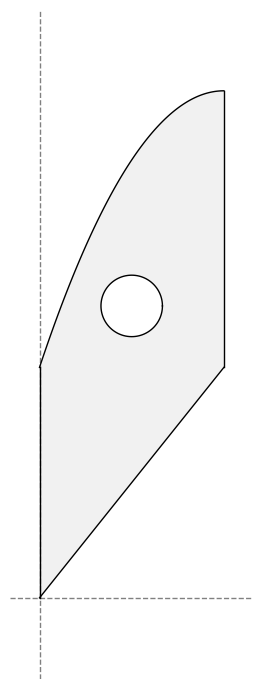


# ------------------------------------------------------------ #
# ------------------------ Resultados ------------------------ #
# ------------------------------------------------------------ #

Área da seção:
A = 22.143,36 cm²

# ----- Resultados em relação aos eixos de referência:  ------ #

Coordenadas (xc, yc) do centróide:
xc = 61,63 cm
yc = 174,23 cm

Momentos estáticos de 1ª ordem:
Sx = 3.858.038,96 cm³
Sy = 1.364.601,78 cm³

Momentos de inércia de área:
Ix = 797.442.024,09 cm⁴
Iy = 110.262.442,87 cm⁴

Produto de inércia:
Pxy = 273.710.337,50 cm⁴

# -------- Resultados em relação aos eixos centrais:  -------- #

Momentos de inércia centrais de área:
Ixc = 125.255.751,15 cm⁴
Iyc = 26.167.808,60 cm⁴

Produto de inércia central:
Pxcyc = 35.955.718,64 cm⁴

Momentos principais centrais de inércia:
I,max = 136.927.944,35 cm⁴
I,min = 14.495.615,40 cm⁴

Eixos principais centrais de inércia:
θ1 = -17,98° (associado a I,max)
θ2 = 72,02° (associado a I,min)





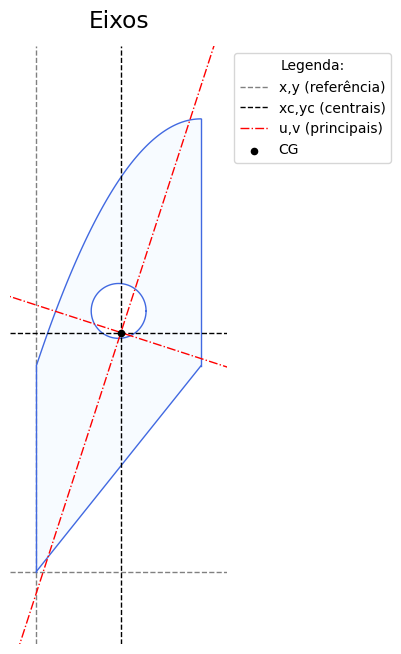

In [4]:
# Opções de visualização da figura inicial, com a seção limpa:
tamanho_figura_i    = 8                   # 3 a 20, padrão 8
cor_figura_i        = 'black'             # ou use a função choose_color(R,G,B)
espessura_figura_i  = 1                   # 0.5 a 3, padrão 0.5
eixos_ref_figura_i  = True                # True or False, padrão False
preenchimento_i     = True                # True or False, padrão True
cor_preenchimento_i = 'gainsboro'         # ou use a função choose_color(R,G,B)
opacidade_i         = 0.4                 # opacidade do preenchimento

# Opções de visualização da figura com os eixos principais:
tamanho_figura_e      = 12                # 3 a 20, padrão 8
cor_figura_e          = 'royalblue'       # ou use a função choose_color(R,G,B)
espessura_figura_e    = 1                 # 0.5 a 3, padrão 1
eixos_ref_figura_e    = True              # True or False, padrão True
preenchimento_e       = True              # True or False, padrão True
cor_preenchimento_e   = 'aliceblue'       # ou use a função choose_color(R,G,B)
opacidade_e           = 0.5               # opacidade do preenchimento


# Salvar arquivos na pasta destino? (True or False)
salvar_fig_inicial          = True  # Figura inicial (seção limpa) em formato .png e .svg
salvar_fig_eixos            = True  # Figura final (eixos principais) em formato .png e .svg
salvar_resultados           = True  # Resultados principais em 'resultados_green.txt'
salvar_resultados_parciais  = True  # Resultados por contorno/furo em 'resultados_parciais.txt'

# Chama função de geração de resultados
resultados_jupyter(ntot, n_sup, c, salvar_fig_inicial, salvar_fig_eixos, salvar_resultados,
                   salvar_resultados_parciais, tamanho_figura_i, cor_figura_i,
                   espessura_figura_i,eixos_ref_figura_i, tamanho_figura_e, cor_figura_e,
                   espessura_figura_e, eixos_ref_figura_e, nome_da_secao, unidades,
                   separador_decimal, separador_milhar,
                   preenchimento_i, cor_preenchimento_i, opacidade_i,
                   preenchimento_e, cor_preenchimento_e, opacidade_e)                       